In [2]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# -------------------- 1. Reproducibility and settings --------------------
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device("cpu")
EPSILONS = [0.05, 0.10, 0.20, 0.30]
BATCH_SIZE = 64

transform = transforms.ToTensor()  # MNIST pixels are in [0, 1]

train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.88MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 150kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.45MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.21MB/s]


In [3]:
# -------------------- 2. CNN model --------------------
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.pool(x)
        x = self.relu(self.conv2(x))
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        x = self.relu(self.fc1(x))
        return self.fc2(x)

model = CNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)


In [4]:
# -------------------- 3. Training baseline --------------------
def train_baseline(model, loader, epochs=2):
    model.train()
    for epoch in range(epochs):
        running_loss = 0.0
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        print(f"Baseline Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(loader):.4f}")

In [5]:
# -------------------- 4. Accuracy evaluation --------------------
def accuracy(model, loader, attack=None, epsilon=0.0):
    model.eval()
    correct, total = 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        if attack is not None:
            images = attack(model, images, labels, epsilon)
        with torch.no_grad():
            predictions = model(images).argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)
    return 100.0 * correct / total

Training baseline CNN (2 epochs)...
Baseline Epoch 1/2, Loss: 0.1848
Baseline Epoch 2/2, Loss: 0.0507
Clean test accuracy: 98.49%
epsilon=0.05 | FGSM: 95.92% | PGD: 95.45%
epsilon=0.10 | FGSM: 88.53% | PGD: 82.19%
epsilon=0.20 | FGSM: 49.60% | PGD: 6.01%
epsilon=0.30 | FGSM: 10.37% | PGD: 0.00%


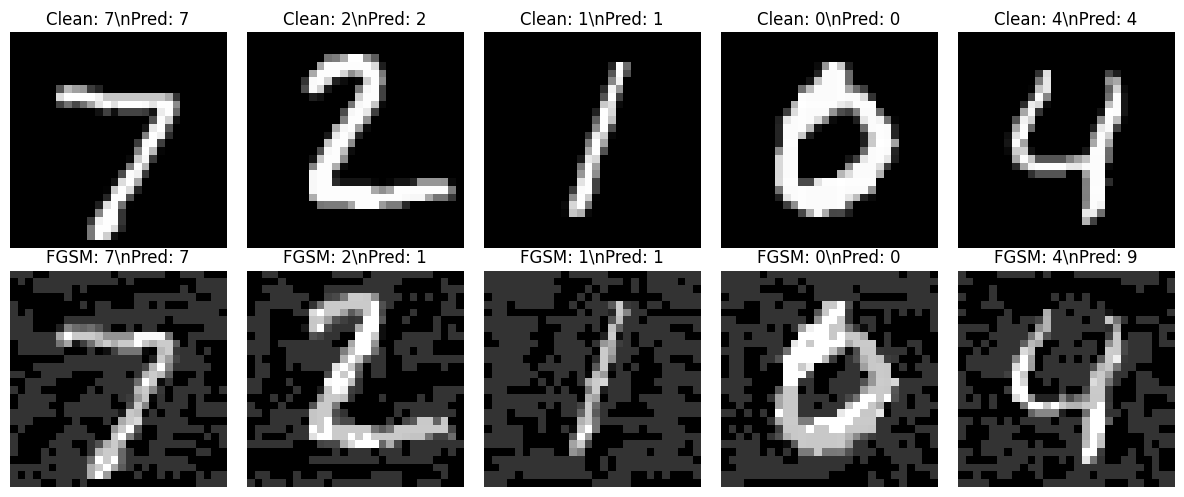

Saved figure: clean_vs_adversarial.png
Image 2: mis-read 2 as 1
Image 5: mis-read 4 as 9
\nFine-tuning with 50:50 clean and FGSM examples...
Adversarial Epoch 1/2, Loss: 0.2706
Adversarial Epoch 2/2, Loss: 0.1646
\nBaseline vs Adversarially trained model:
MODEL                        CLEAN     FGSM(0.20)      PGD(0.20)
----------------------------------------------------------------
Baseline                    98.49%         49.60%          6.01%
Adversarially trained       98.90%         92.99%         21.00%
Clean accuracy change: +0.41 percentage points
FGSM robustness gain: +43.39 percentage points
PGD robustness gain: +14.99 percentage points


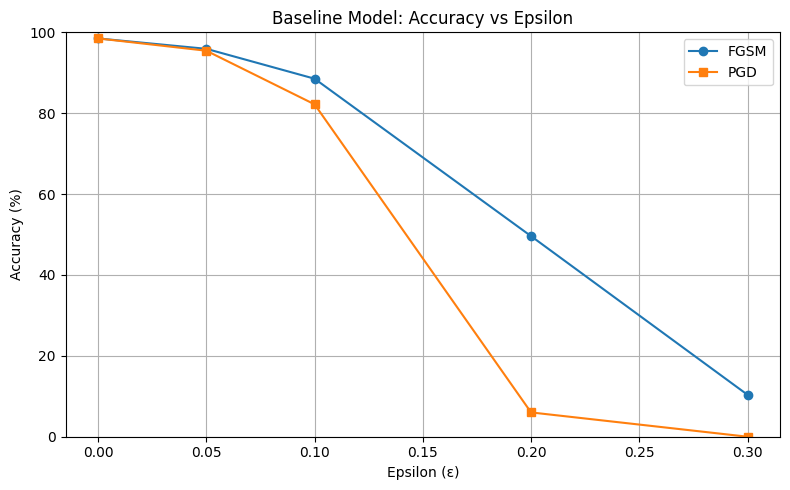

Saved figure: accuracy_vs_epsilon.png
Saved results: results.txt
Saved model: mnist_adv_trained_model.pth
\nPractical completed.


In [6]:
# -------------------- 5. FGSM attack --------------------
def fgsm_attack(model, images, labels, epsilon):
    images = images.detach().clone().to(device)
    labels = labels.to(device)
    images.requires_grad_(True)

    outputs = model(images)
    loss = criterion(outputs, labels)
    model.zero_grad()
    loss.backward()

    perturbed = images + epsilon * images.grad.sign()
    perturbed = torch.clamp(perturbed, 0.0, 1.0)
    return perturbed.detach()

# -------------------- 6. PGD attack (L-infinity) --------------------
def pgd_attack(model, images, labels, epsilon, iterations=10, alpha=None):
    if alpha is None:
        alpha = epsilon / 4.0

    original = images.detach().clone().to(device)
    labels = labels.to(device)

    # Random start within the epsilon ball
    perturbed = original + torch.empty_like(original).uniform_(-epsilon, epsilon)
    perturbed = torch.clamp(perturbed, 0.0, 1.0)

    for _ in range(iterations):
        perturbed.requires_grad_(True)
        outputs = model(perturbed)
        loss = criterion(outputs, labels)
        model.zero_grad()
        loss.backward()

        with torch.no_grad():
            perturbed = perturbed + alpha * perturbed.grad.sign()
            # Project back into the epsilon L-infinity ball around original
            perturbed = torch.max(torch.min(perturbed, original + epsilon),
                                  original - epsilon)
            perturbed = torch.clamp(perturbed, 0.0, 1.0)
        perturbed = perturbed.detach()

    return perturbed

# -------------------- 7. Baseline results --------------------
print("Training baseline CNN (2 epochs)...")
train_baseline(model, train_loader, epochs=2)
clean_acc = accuracy(model, test_loader)
print(f"Clean test accuracy: {clean_acc:.2f}%")

fgsm_results, pgd_results = [], []
for eps in EPSILONS:
    fgsm_acc = accuracy(model, test_loader, fgsm_attack, eps)
    pgd_acc = accuracy(model, test_loader, pgd_attack, eps)
    fgsm_results.append(fgsm_acc)
    pgd_results.append(pgd_acc)
    print(f"epsilon={eps:.2f} | FGSM: {fgsm_acc:.2f}% | PGD: {pgd_acc:.2f}%")

# -------------------- 8. Display 5 clean vs FGSM images --------------------
model.eval()
images, labels = next(iter(test_loader))
images, labels = images.to(device), labels.to(device)
adv_images = fgsm_attack(model, images, labels, epsilon=0.20)

with torch.no_grad():
    clean_preds = model(images).argmax(dim=1)
    adv_preds = model(adv_images).argmax(dim=1)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i in range(5):
    axes[0, i].imshow(images[i].squeeze().cpu(), cmap="gray")
    axes[0, i].set_title(f"Clean: {labels[i].item()}\\nPred: {clean_preds[i].item()}")
    axes[0, i].axis("off")

    axes[1, i].imshow(adv_images[i].squeeze().cpu(), cmap="gray")
    axes[1, i].set_title(f"FGSM: {labels[i].item()}\\nPred: {adv_preds[i].item()}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.savefig("clean_vs_adversarial.png", dpi=150)
plt.show()
print("Saved figure: clean_vs_adversarial.png")
for i in range(5):
    if clean_preds[i].item() != adv_preds[i].item():
        print(f"Image {i+1}: mis-read {labels[i].item()} as {adv_preds[i].item()}")

# -------------------- 9. Adversarial training (50:50 clean/FGSM) --------------------
def adversarial_train(model, loader, epochs=2, epsilon=0.20):
    adv_optimizer = optim.Adam(model.parameters(), lr=0.001)
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            half = images.size(0) // 2
            clean_half = images[:half]
            labels_half = labels[:half]

            # Generate FGSM adversarial examples from half of the batch
            adv_half = fgsm_attack(model, clean_half, labels_half, epsilon)

            # 50:50 mixture of clean and adversarial samples
            mixed_images = torch.cat((clean_half, adv_half), dim=0)
            mixed_labels = torch.cat((labels_half, labels_half), dim=0)

            adv_optimizer.zero_grad()
            outputs = model(mixed_images)
            loss = criterion(outputs, mixed_labels)
            loss.backward()
            adv_optimizer.step()
            running_loss += loss.item()

        print(f"Adversarial Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(loader):.4f}")

print("\\nFine-tuning with 50:50 clean and FGSM examples...")
adversarial_train(model, train_loader, epochs=2, epsilon=0.20)

# -------------------- 10. Re-evaluate at epsilon 0.20 --------------------
adv_clean_acc = accuracy(model, test_loader)
adv_fgsm_acc = accuracy(model, test_loader, fgsm_attack, 0.20)
adv_pgd_acc = accuracy(model, test_loader, pgd_attack, 0.20)

print("\\nBaseline vs Adversarially trained model:")
print(f"{'MODEL':<24}{'CLEAN':>10}{'FGSM(0.20)':>15}{'PGD(0.20)':>15}")
print("-" * 64)
print(f"{'Baseline':<24}{clean_acc:>9.2f}%{fgsm_results[2]:>14.2f}%{pgd_results[2]:>14.2f}%")
print(f"{'Adversarially trained':<24}{adv_clean_acc:>9.2f}%{adv_fgsm_acc:>14.2f}%{adv_pgd_acc:>14.2f}%")

print(f"Clean accuracy change: {adv_clean_acc-clean_acc:+.2f} percentage points")
print(f"FGSM robustness gain: {adv_fgsm_acc-fgsm_results[2]:+.2f} percentage points")
print(f"PGD robustness gain: {adv_pgd_acc-pgd_results[2]:+.2f} percentage points")

# -------------------- 11. Plot baseline accuracy vs epsilon --------------------
eps_plot = [0.0] + EPSILONS
fgsm_plot = [clean_acc] + fgsm_results
pgd_plot = [clean_acc] + pgd_results

plt.figure(figsize=(8, 5))
plt.plot(eps_plot, fgsm_plot, marker="o", label="FGSM")
plt.plot(eps_plot, pgd_plot, marker="s", label="PGD")
plt.xlabel("Epsilon (ε)")
plt.ylabel("Accuracy (%)")
plt.title("Baseline Model: Accuracy vs Epsilon")
plt.ylim(0, 100)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("accuracy_vs_epsilon.png", dpi=150)
plt.show()
print("Saved figure: accuracy_vs_epsilon.png")

# -------------------- 12. Save results table --------------------
with open("results.txt", "w", encoding="utf-8") as f:
    f.write("Baseline Model under Attack\\n")
    f.write(f"Clean accuracy: {clean_acc:.2f}%\\n")
    f.write("Epsilon | FGSM Accuracy | PGD Accuracy\\n")
    for eps, f_acc, p_acc in zip(EPSILONS, fgsm_results, pgd_results):
        f.write(f"{eps:.2f} | {f_acc:.2f}% | {p_acc:.2f}%\\n")
    f.write("\\nBaseline vs Adversarially Trained at epsilon 0.20\\n")
    f.write(f"Baseline: Clean {clean_acc:.2f}%, FGSM {fgsm_results[2]:.2f}%, PGD {pgd_results[2]:.2f}%\\n")
    f.write(f"Adversarially trained: Clean {adv_clean_acc:.2f}%, FGSM {adv_fgsm_acc:.2f}%, PGD {adv_pgd_acc:.2f}%\\n")
print("Saved results: results.txt")

# Save final model weights
torch.save(model.state_dict(), "mnist_adv_trained_model.pth")
print("Saved model: mnist_adv_trained_model.pth")
print("\\nPractical completed.")
